In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
import tensorflow as tf
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


Please cite as the Introductory Papers: Sathishkumar, V. E., Park, J., & Cho, Y. (2020). Using data mining techniques for bike sharing demand prediction in metropolitan city. Computer Communications, 153, 353–366. https://doi.org/10.1016/j.comcom.2020.02.007 Sathishkumar, V. E., & Cho, Y. (2020). A rule-based model for Seoul Bike sharing demand prediction using weather data. European Journal of Remote Sensing, 53(sup1), 166–183. https://doi.org/10.1080/22797254.2020.1725789

In [2]:
df = pd.read_csv(r'/content/SeoulBikeData.csv', encoding="cp1252")

In [3]:
df.shape

(8760, 14)

In [4]:
df.drop(columns='Date',inplace=True)

In [5]:
df_cols= ['Bike count','hours','Temp', 'Humidity','Wind', 'Visibility','Dew_pt','Radiation','Rain','Snowfall','Seasons','Holiday','functional']
df.columns=df_cols

In [6]:
df.head()

,Bike count,hours,Temp,Humidity,Wind,Visibility,Dew_pt,Radiation,Rain,Snowfall,Seasons,Holiday,functional
0,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [7]:
df['functional']=(df['functional']=='Yes').astype(int)


In [8]:
df['Holiday'] = (df['Holiday']=='Holiday').astype(int)

In [9]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
le.fit_transform(df['Seasons'])

array([3, 3, 3, ..., 0, 0, 0], shape=(8760,))

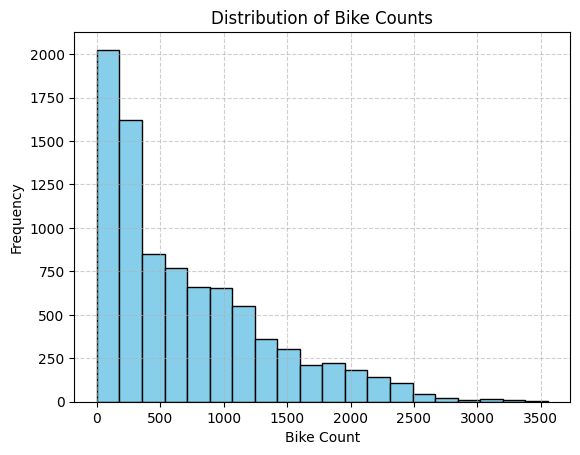

In [10]:
plt.hist(df['Bike count'], bins=20, color='skyblue', edgecolor='black')
plt.title('Distribution of Bike Counts')
plt.xlabel('Bike Count')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


In [17]:
le = LabelEncoder()
df['Seasons']=le.fit_transform(df['Seasons'])

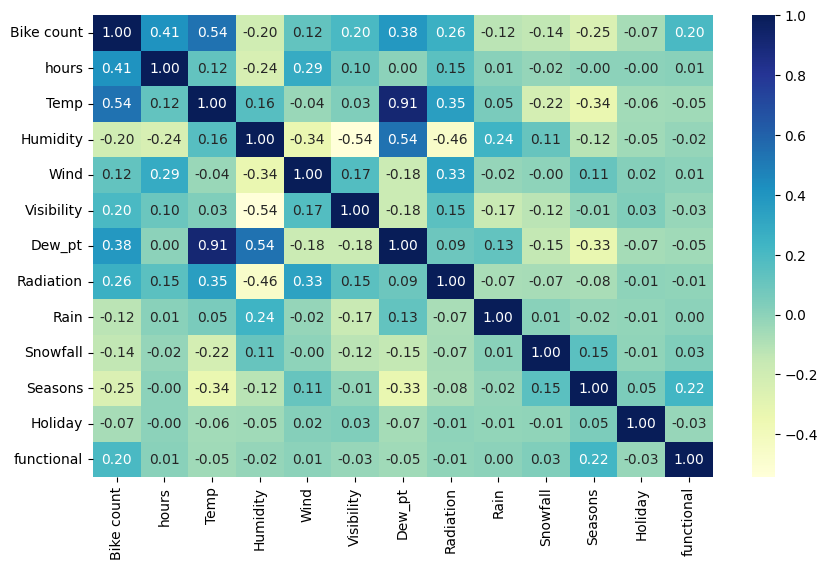

In [32]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(),annot= True, cmap='YlGnBu',fmt ='.2f')
plt.show()

In [33]:
df = df.drop(['Dew_pt'],axis=1)

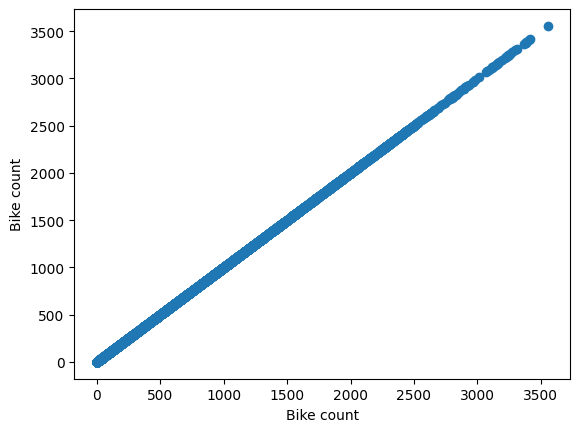

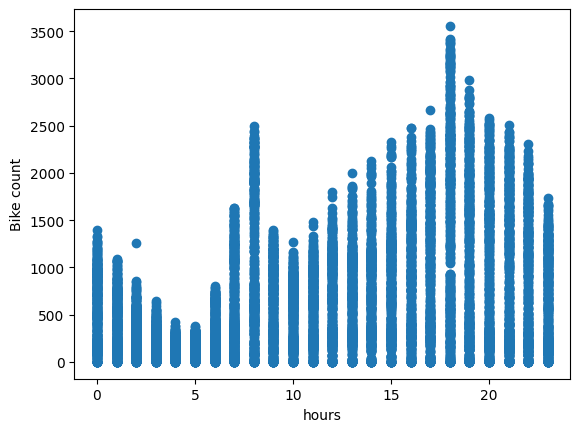

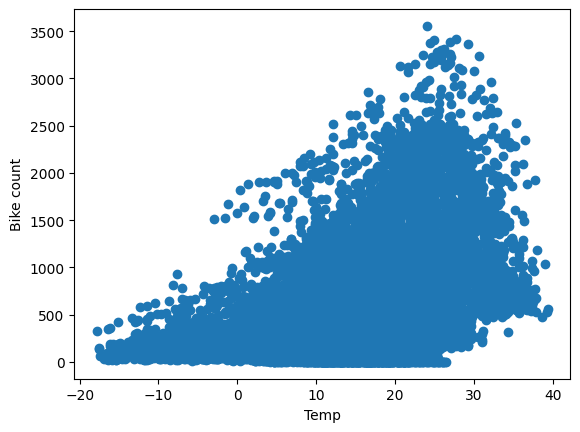

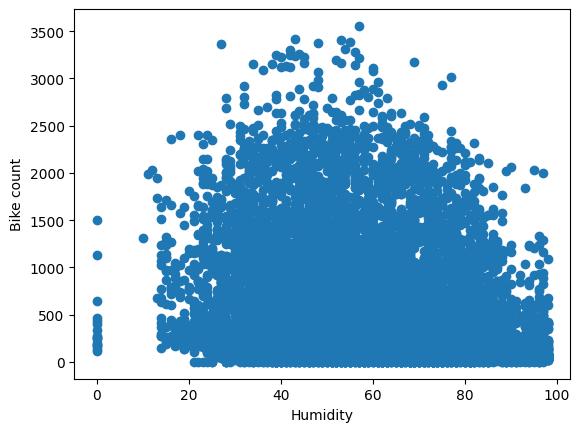

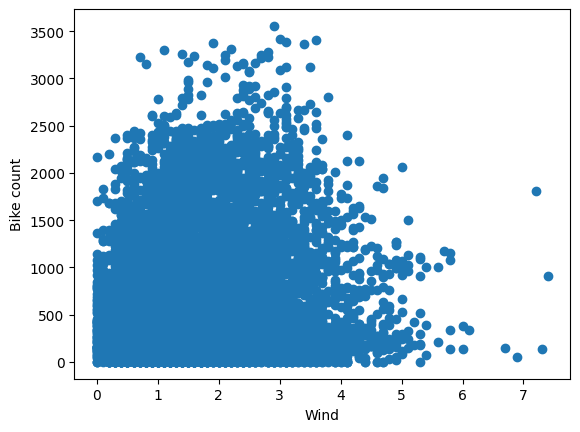

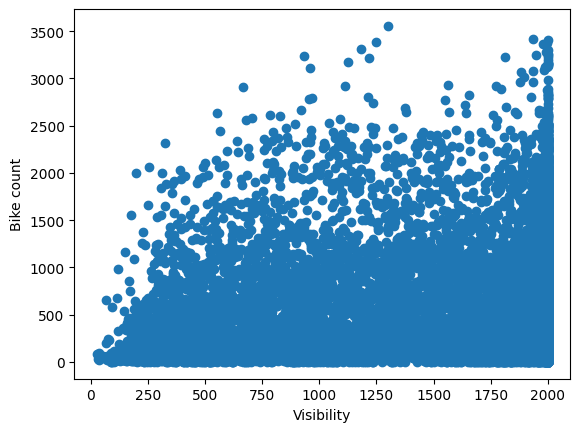

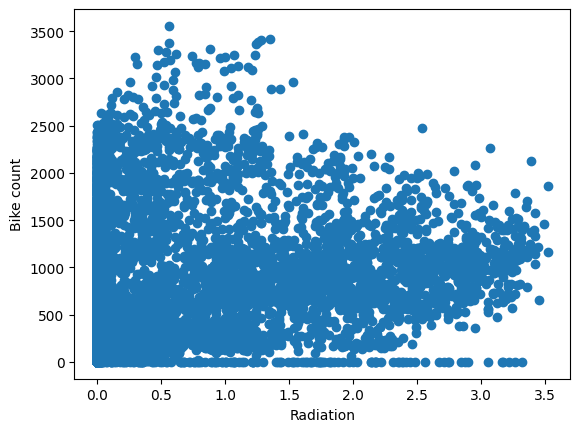

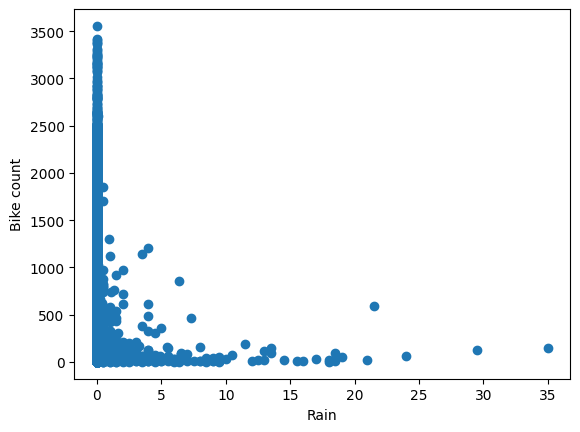

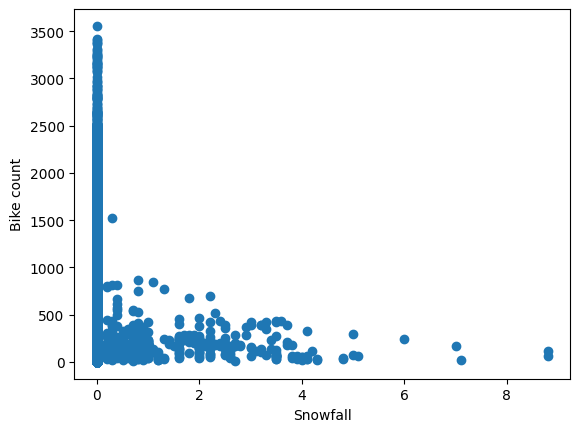

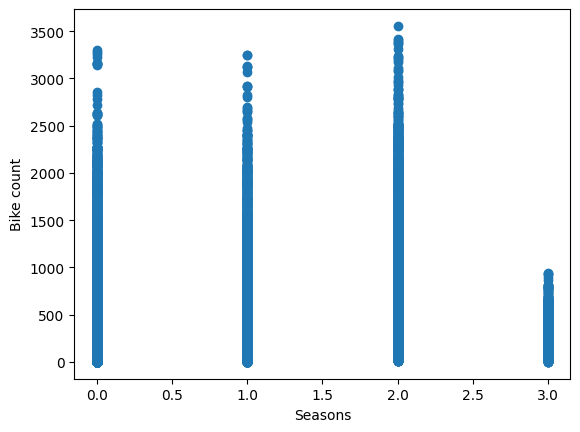

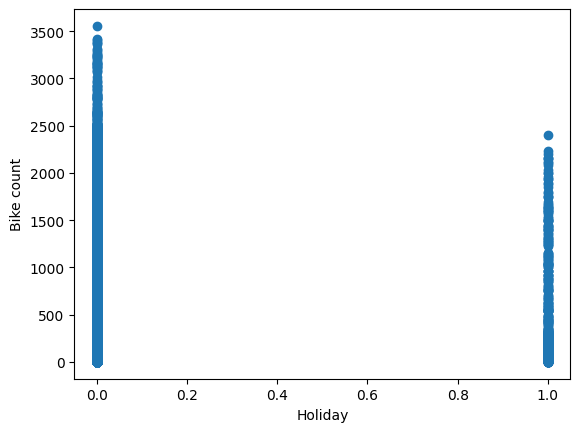

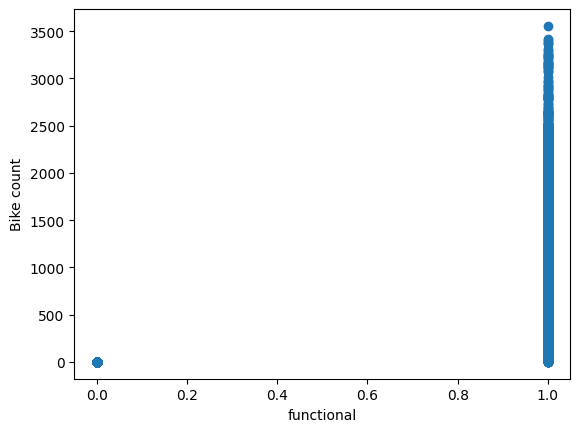

In [41]:
for i in df.columns:
  plt.scatter(df[i],df['Bike count'])
  plt.xlabel(i)
  plt.ylabel('Bike count')
  plt.show()

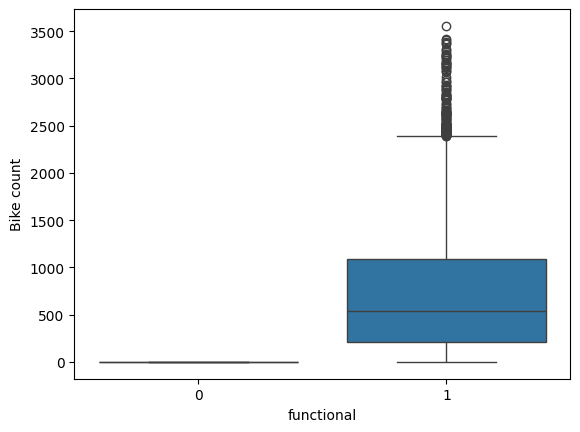

In [44]:
sns.boxplot(x=df['functional'],y= df['Bike count'])
plt.xlabel('functional')
plt.ylabel('Bike count')
plt.show()

In [36]:
X = df.drop(columns='Bike count',axis=1)
y = df['Bike count']

In [46]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)


In [47]:
linear_model = LinearRegression()
linear_model.fit(X_train,y_train)

LinearRegression()

In [67]:
y_pred = linear_model.predict(X_test)
# y_pred = y_pred.reshape(-1,1)

In [73]:
linear_model.score(X_test,y_test)

0.5316819355443251

In [74]:
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor()
rf_model.fit(X_train,y_train)

RandomForestRegressor()

In [76]:
y_pred = rf_model.predict(X_test)

In [78]:
rf_model.score(X_test,y_test)

0.861334080196306

In [80]:
print(mean_squared_error(y_test,y_pred))
print(r2_score(y_test,y_pred))

57774.63378458904
0.861334080196306
